### **Naveed Anjum (Reg # 577607)**
##### Oct 18, 2026
---
## **Tutorial 13: Denoising Autoencoders**

## 1. Import Libraries

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


## 2. Load and Prepare the MNIST Dataset

In [2]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)
test_dataset = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

# Use a smaller subset to keep the tutorial quick and simple.
# Set these to the full dataset sizes (60000 and 10000) if desired.
train_size = 10000
test_size = 2000

train_images = torch.stack([train_dataset[i][0] for i in range(train_size)])
test_images = torch.stack([test_dataset[i][0] for i in range(test_size)])

print("Training images:", train_images.shape)
print("Testing images:", test_images.shape)

100%|██████████| 9.91M/9.91M [00:00<00:00, 40.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.04MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.02MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.37MB/s]


Training images: torch.Size([10000, 1, 28, 28])
Testing images: torch.Size([2000, 1, 28, 28])


## 3. Add Noise to the Images

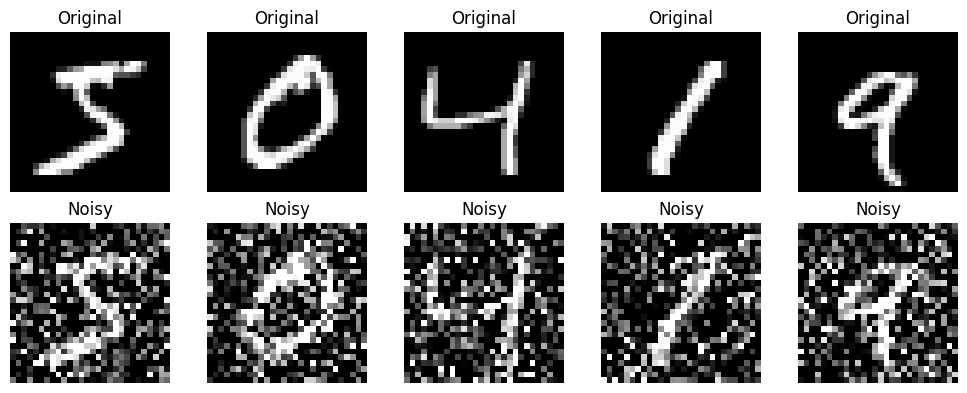

In [3]:
def add_noise(images, noise_factor=0.5):
    noise = noise_factor * torch.randn_like(images)
    noisy_images = images + noise
    noisy_images = torch.clamp(noisy_images, 0.0, 1.0)
    return noisy_images

train_noisy = add_noise(train_images)
test_noisy = add_noise(test_images)

# Display a few clean and noisy images
plt.figure(figsize=(10, 4))
for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(train_images[i].squeeze(), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, 5, i + 6)
    plt.imshow(train_noisy[i].squeeze(), cmap="gray")
    plt.title("Noisy")
    plt.axis("off")
plt.tight_layout()
plt.show()

## 4. Build the Convolutional Denoising Autoencoder

In [4]:
class DenoisingAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),             # 28 x 28 -> 14 x 14

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)              # 14 x 14 -> 7 x 7
        )

        # Decoder
        self.decoder = nn.Sequential(
            nn.Upsample(scale_factor=2, mode="nearest"),  # 7 x 7 -> 14 x 14
            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Upsample(scale_factor=2, mode="nearest"),  # 14 x 14 -> 28 x 28
            nn.Conv2d(32, 1, kernel_size=3, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x


model = DenoisingAutoencoder().to(device)
print(model)

DenoisingAutoencoder(
  (encoder): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (decoder): Sequential(
    (0): Upsample(scale_factor=2.0, mode='nearest')
    (1): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (2): ReLU()
    (3): Upsample(scale_factor=2.0, mode='nearest')
    (4): Conv2d(32, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): Sigmoid()
  )
)


## 5. Train the Denoising Autoencoder

In [5]:
batch_size = 128

train_loader = DataLoader(
    TensorDataset(train_noisy, train_images),
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    TensorDataset(test_noisy, test_images),
    batch_size=batch_size,
    shuffle=False
)

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 5  # Increase to 10 or more for better results

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for noisy, clean in train_loader:
        noisy = noisy.to(device)
        clean = clean.to(device)

        # Forward pass
        reconstructed = model(noisy)
        loss = criterion(reconstructed, clean)

        # Backward pass and update weights
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch [{epoch + 1}/{epochs}], Loss: {total_loss / len(train_loader):.4f}")

Epoch [1/5], Loss: 0.1197
Epoch [2/5], Loss: 0.1125
Epoch [3/5], Loss: 0.1124
Epoch [4/5], Loss: 0.1125
Epoch [5/5], Loss: 0.1124


## 6. Evaluate and Visualize the Results

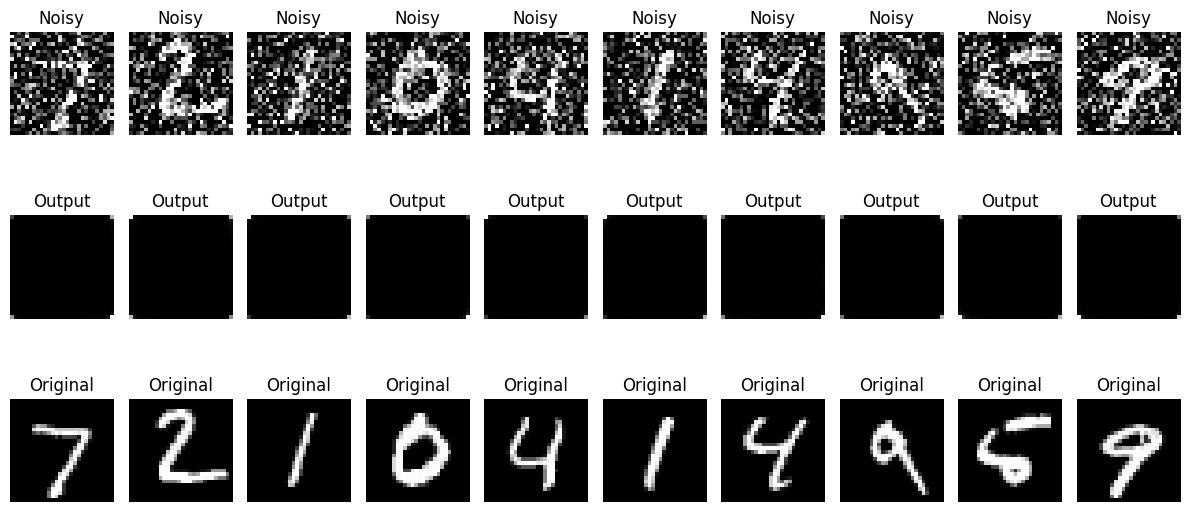

In [6]:
model.eval()
with torch.no_grad():
    sample_noisy = test_noisy[:10].to(device)
    reconstructed_images = model(sample_noisy).cpu()

plt.figure(figsize=(12, 6))
for i in range(10):
    # Noisy input
    plt.subplot(3, 10, i + 1)
    plt.imshow(test_noisy[i].squeeze(), cmap="gray")
    plt.title("Noisy")
    plt.axis("off")

    # Reconstructed output
    plt.subplot(3, 10, i + 11)
    plt.imshow(reconstructed_images[i].squeeze(), cmap="gray")
    plt.title("Output")
    plt.axis("off")

    # Original clean image
    plt.subplot(3, 10, i + 21)
    plt.imshow(test_images[i].squeeze(), cmap="gray")
    plt.title("Original")
    plt.axis("off")

plt.tight_layout()
plt.show()

# Tutorial Tasks

## 7. Task 1 — Implementing a Deep Autoencoder

In [7]:
class DeepAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        # Encoder: gradually compress the image
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU()
        )

        # Decoder: reconstruct the image
        self.decoder = nn.Sequential(
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 28 * 28),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x.view(-1, 1, 28, 28)


deep_model = DeepAutoencoder().to(device)
print(deep_model)

DeepAutoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=64, bias=True)
    (6): ReLU()
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


In [8]:
deep_optimizer = optim.Adam(deep_model.parameters(), lr=0.001)
deep_criterion = nn.MSELoss()

for epoch in range(5):
    deep_model.train()
    total_loss = 0

    for noisy, clean in train_loader:
        noisy = noisy.to(device)
        clean = clean.to(device)

        output = deep_model(noisy)
        loss = deep_criterion(output, clean)

        deep_optimizer.zero_grad()
        loss.backward()
        deep_optimizer.step()

        total_loss += loss.item()

    print(f"Deep AE Epoch [{epoch + 1}/5], Loss: {total_loss / len(train_loader):.4f}")

Deep AE Epoch [1/5], Loss: 0.0893
Deep AE Epoch [2/5], Loss: 0.0674
Deep AE Epoch [3/5], Loss: 0.0617
Deep AE Epoch [4/5], Loss: 0.0587
Deep AE Epoch [5/5], Loss: 0.0544


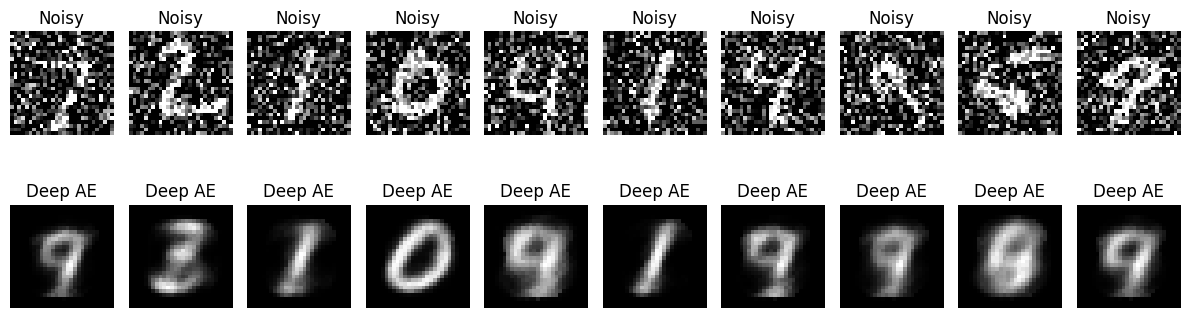

In [9]:
# Visualize Deep Autoencoder output
deep_model.eval()
with torch.no_grad():
    deep_output = deep_model(test_noisy[:10].to(device)).cpu()

plt.figure(figsize=(12, 4))
for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(test_noisy[i].squeeze(), cmap="gray")
    plt.title("Noisy")
    plt.axis("off")

    plt.subplot(2, 10, i + 11)
    plt.imshow(deep_output[i].squeeze(), cmap="gray")
    plt.title("Deep AE")
    plt.axis("off")

plt.tight_layout()
plt.show()

## 8. Task 2 — Implementing a Variational Autoencoder (VAE)

In [10]:
class VariationalAutoencoder(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU()
        )

        # Mean and log variance of latent distribution
        self.fc_mu = nn.Linear(128, latent_dim)
        self.fc_log_var = nn.Linear(128, latent_dim)

        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 28 * 28),
            nn.Sigmoid()
        )

    def reparameterize(self, mu, log_var):
        std = torch.exp(0.5 * log_var)
        random_noise = torch.randn_like(std)
        return mu + random_noise * std

    def forward(self, x):
        encoded = self.encoder(x)
        mu = self.fc_mu(encoded)
        log_var = self.fc_log_var(encoded)

        z = self.reparameterize(mu, log_var)
        decoded = self.decoder(z)
        decoded = decoded.view(-1, 1, 28, 28)

        return decoded, mu, log_var


vae = VariationalAutoencoder(latent_dim=32).to(device)
print(vae)

VariationalAutoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
  )
  (fc_mu): Linear(in_features=128, out_features=32, bias=True)
  (fc_log_var): Linear(in_features=128, out_features=32, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=32, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


### Train the Variational Autoencoder

In [11]:
vae_optimizer = optim.Adam(vae.parameters(), lr=0.001)

for epoch in range(5):
    vae.train()
    total_loss = 0

    for noisy, clean in train_loader:
        noisy = noisy.to(device)
        clean = clean.to(device)

        output, mu, log_var = vae(noisy)

        # Reconstruction loss
        reconstruction_loss = nn.functional.binary_cross_entropy(
            output, clean, reduction="sum"
        )

        # KL divergence loss
        kl_loss = -0.5 * torch.sum(
            1 + log_var - mu.pow(2) - log_var.exp()
        )

        loss = reconstruction_loss + kl_loss

        vae_optimizer.zero_grad()
        loss.backward()
        vae_optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader.dataset)
    print(f"VAE Epoch [{epoch + 1}/5], Loss per image: {average_loss:.4f}")

VAE Epoch [1/5], Loss per image: 254.5933
VAE Epoch [2/5], Loss per image: 201.8860
VAE Epoch [3/5], Loss per image: 196.3282
VAE Epoch [4/5], Loss per image: 194.5903
VAE Epoch [5/5], Loss per image: 192.9195


### Visualize VAE Results

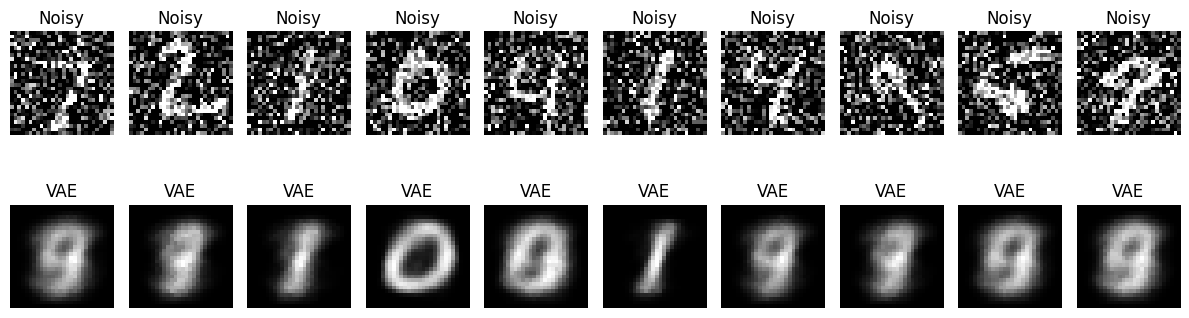

In [12]:
vae.eval()
with torch.no_grad():
    vae_output, _, _ = vae(test_noisy[:10].to(device))
    vae_output = vae_output.cpu()

plt.figure(figsize=(12, 4))
for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(test_noisy[i].squeeze(), cmap="gray")
    plt.title("Noisy")
    plt.axis("off")

    plt.subplot(2, 10, i + 11)
    plt.imshow(vae_output[i].squeeze(), cmap="gray")
    plt.title("VAE")
    plt.axis("off")

plt.tight_layout()
plt.show()